### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [3]:
data = pd.read_csv('data/coupons.csv')

In [4]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [5]:
# Check the dataset information and missing values
data.info()
data.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  car                   108 non-null    str  
 15  Bar                   12577 non-null  str  
 16  CoffeeHouse    

destination                 0
passanger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64

3. Decide what to do about your missing data -- drop, replace, other...

In [6]:
# Drop the car column because nearly all of its values are missing
data = data.drop(columns=['car'])

# Drop rows containing the remaining missing values
data = data.dropna()

# Confirm that the missing values were removed
data.isnull().sum()

destination             0
passanger               0
weather                 0
temperature             0
time                    0
coupon                  0
expiration              0
gender                  0
age                     0
maritalStatus           0
has_children            0
education               0
occupation              0
income                  0
Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
toCoupon_GEQ5min        0
toCoupon_GEQ15min       0
toCoupon_GEQ25min       0
direction_same          0
direction_opp           0
Y                       0
dtype: int64

4. What proportion of the total observations chose to accept the coupon?



In [7]:
# Count the accepted coupons and calculate the proportion
accepted_coupons = (data['Y'] == 1).sum()
total_coupons = len(data)

acceptance_proportion = accepted_coupons / total_coupons

print(acceptance_proportion)

0.5693352098683666


5. Use a bar plot to visualize the `coupon` column.

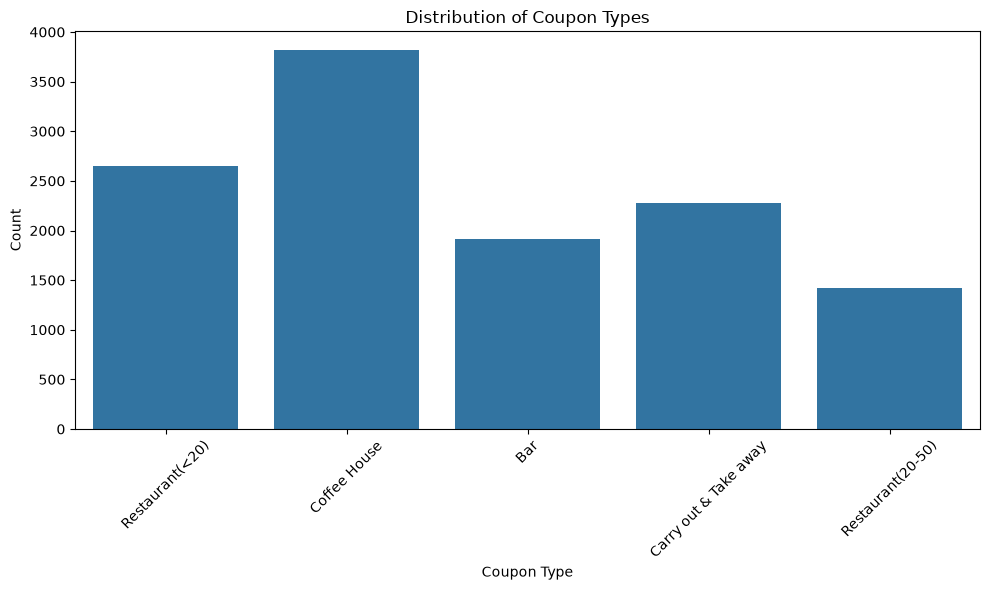

In [8]:
# Create a bar plot showing the number of each coupon type
plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='coupon')

plt.title('Distribution of Coupon Types')
plt.xlabel('Coupon Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

6. Use a histogram to visualize the temperature column.

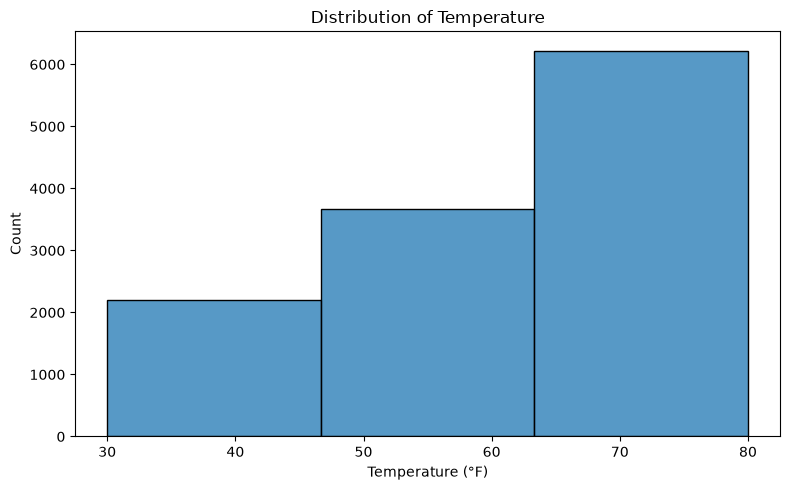

In [9]:
# Create a histogram of the temperature column
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x='temperature', bins=3)

plt.title('Distribution of Temperature')
plt.xlabel('Temperature (°F)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [10]:
# Create a DataFrame containing only bar coupons
bar_coupons = data.loc[data['coupon'] == 'Bar']

bar_coupons.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1
39,Work,Alone,Sunny,55,7AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,1,1,0,1,1
46,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,46,Single,...,4~8,1~3,1~3,never,1,0,0,0,1,0
57,Home,Alone,Sunny,55,6PM,Bar,1d,Male,46,Single,...,4~8,1~3,1~3,never,1,0,0,1,0,0


2. What proportion of bar coupons were accepted?


In [11]:
# Calculate the proportion of bar coupons that were accepted
accepted_bar_coupons = (bar_coupons['Y'] == 1).sum()
total_bar_coupons = len(bar_coupons)

bar_acceptance_rate = accepted_bar_coupons / total_bar_coupons

print(bar_acceptance_rate)

0.41191845269210664


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [12]:
# Separate drivers by how often they visit a bar
three_or_fewer = bar_coupons.loc[
    bar_coupons['Bar'].isin(['never', 'less1', '1~3'])
]

more_than_three = bar_coupons.loc[
    bar_coupons['Bar'].isin(['4~8', 'gt8'])
]

# Calculate the acceptance rate for each group
three_or_fewer_rate = (three_or_fewer['Y'] == 1).sum() / len(three_or_fewer)
more_than_three_rate = (more_than_three['Y'] == 1).sum() / len(more_than_three)

print("Acceptance rate for 3 or fewer visits:", three_or_fewer_rate)
print("Acceptance rate for more than 3 visits:", more_than_three_rate)

Acceptance rate for 3 or fewer visits: 0.37267441860465117
Acceptance rate for more than 3 visits: 0.7616580310880829


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [13]:
# Identify drivers over 25 who visit a bar more than once a month
frequent_older_condition = (
    bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8']) &
    (bar_coupons['age'] != 'below21') &
    (bar_coupons['age'] != '21')
)

frequent_older = bar_coupons.loc[frequent_older_condition]
all_others = bar_coupons.loc[~frequent_older_condition]

# Calculate the acceptance rate for each group
frequent_older_rate = (frequent_older['Y'] == 1).sum() / len(frequent_older)
all_others_rate = (all_others['Y'] == 1).sum() / len(all_others)

print("Acceptance rate for frequent bar visitors over 25:", frequent_older_rate)
print("Acceptance rate for all others:", all_others_rate)

Acceptance rate for frequent bar visitors over 25: 0.6898263027295285
Acceptance rate for all others: 0.33774834437086093


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [14]:
# Identify frequent bar visitors without kid passengers
# and who do not work in farming, fishing, or forestry
frequent_no_kids_condition = (
    bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8']) &
    (bar_coupons['passanger'] != 'Kid(s)') &
    (bar_coupons['occupation'] != 'Farming Fishing & Forestry')
)

frequent_no_kids = bar_coupons.loc[frequent_no_kids_condition]
all_other_drivers = bar_coupons.loc[~frequent_no_kids_condition]

# Calculate the acceptance rate for each group
frequent_no_kids_rate = (
    (frequent_no_kids['Y'] == 1).sum() / len(frequent_no_kids)
)

all_other_drivers_rate = (
    (all_other_drivers['Y'] == 1).sum() / len(all_other_drivers)
)

print("Acceptance rate for the selected drivers:", frequent_no_kids_rate)
print("Acceptance rate for all other drivers:", all_other_drivers_rate)

Acceptance rate for the selected drivers: 0.7094339622641509
Acceptance rate for all other drivers: 0.29790310918293567


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [15]:
# Drivers who go to bars more than once a month
frequent_bar_visits = bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])

# First group: not traveling with kids and not widowed
condition_1 = (
    frequent_bar_visits
    & (bar_coupons['passanger'] != 'Kid(s)')
    & (bar_coupons['maritalStatus'] != 'Widowed')
)

# Second group: under age 30
condition_2 = (
    frequent_bar_visits
    & bar_coupons['age'].isin(['below21', '21', '26'])
)

# Third group: visits cheap restaurants more than 4 times per month
# and has an income under $50K
condition_3 = (
    bar_coupons['RestaurantLessThan20'].isin(['4~8', 'gt8'])
    & bar_coupons['income'].isin([
        'Less than $12500',
        '$12500 - $24999',
        '$25000 - $37499',
        '$37500 - $49999'
    ])
)

# Drivers who meet at least one condition
selected_drivers_condition = condition_1 | condition_2 | condition_3

selected_drivers = bar_coupons.loc[selected_drivers_condition]
all_other_drivers = bar_coupons.loc[~selected_drivers_condition]

# Calculate and compare acceptance rates
selected_drivers_rate = (selected_drivers['Y'] == 1).sum() / len(selected_drivers)
all_other_drivers_rate = (all_other_drivers['Y'] == 1).sum() / len(all_other_drivers)

print("Acceptance rate for selected drivers:", selected_drivers_rate)
print("Acceptance rate for all other drivers:", all_other_drivers_rate)

Acceptance rate for selected drivers: 0.5871313672922251
Acceptance rate for all other drivers: 0.29991431019708653


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Based on these observations, I hypothesize that drivers are more likely to accept bar coupons when they already visit bars regularly. Acceptance also appears higher among younger drivers, drivers without child passengers who are not widowed, and drivers who frequently visit inexpensive restaurants with incomes below $50,000. Overall, these groups may be more likely to be interested in going out for food or drinks and therefore find the bar coupon more useful.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [16]:
# Create a DataFrame containing only Coffee House coupons
coffee_coupons = data.loc[data['coupon'] == 'Coffee House']

# Calculate the overall acceptance rate
coffee_accepted = (coffee_coupons['Y'] == 1).sum()
coffee_total = len(coffee_coupons)
coffee_acceptance_rate = coffee_accepted / coffee_total

print("Overall Coffee House coupon acceptance rate:", coffee_acceptance_rate)

Overall Coffee House coupon acceptance rate: 0.49633123689727465


In [17]:
# Separate drivers by how often they visit coffee houses
infrequent_coffee_visitors = coffee_coupons.loc[
    coffee_coupons['CoffeeHouse'].isin(['never', 'less1', '1~3'])
]

frequent_coffee_visitors = coffee_coupons.loc[
    coffee_coupons['CoffeeHouse'].isin(['4~8', 'gt8'])
]

# Calculate acceptance rates
infrequent_rate = (
    (infrequent_coffee_visitors['Y'] == 1).sum()
    / len(infrequent_coffee_visitors)
)

frequent_rate = (
    (frequent_coffee_visitors['Y'] == 1).sum()
    / len(frequent_coffee_visitors)
)

print("Acceptance rate for infrequent coffee house visitors:", infrequent_rate)
print("Acceptance rate for frequent coffee house visitors:", frequent_rate)

Acceptance rate for infrequent coffee house visitors: 0.44590495449949447
Acceptance rate for frequent coffee house visitors: 0.6725559481743227


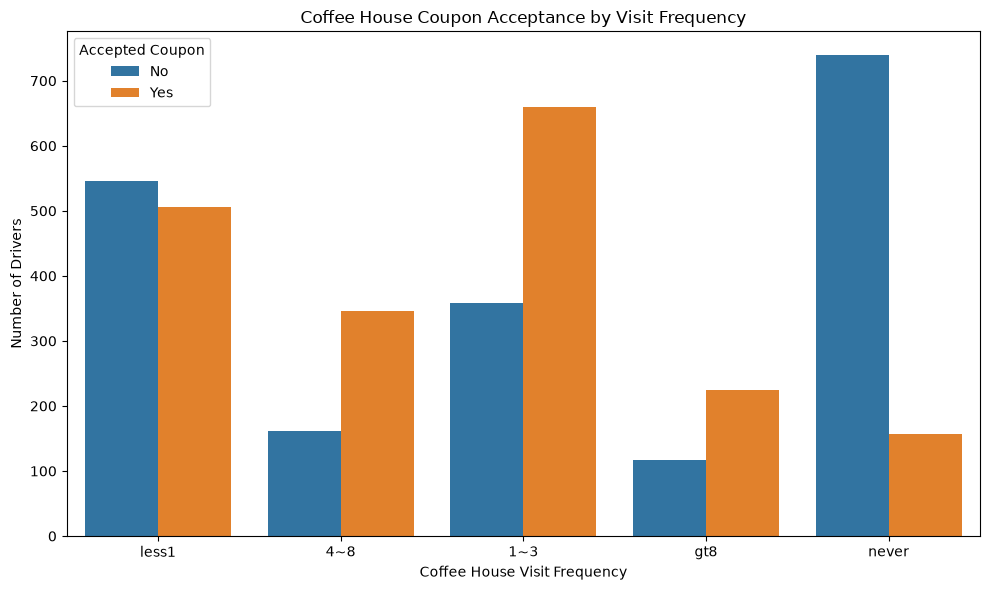

In [18]:
plt.figure(figsize=(10, 6))
sns.countplot(data=coffee_coupons, x='CoffeeHouse', hue='Y')

plt.title('Coffee House Coupon Acceptance by Visit Frequency')
plt.xlabel('Coffee House Visit Frequency')
plt.ylabel('Number of Drivers')
plt.legend(title='Accepted Coupon', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()

passanger
Friend(s)    0.597447
Partner      0.567010
Kid(s)       0.471503
Alone        0.433936
Name: Y, dtype: float64


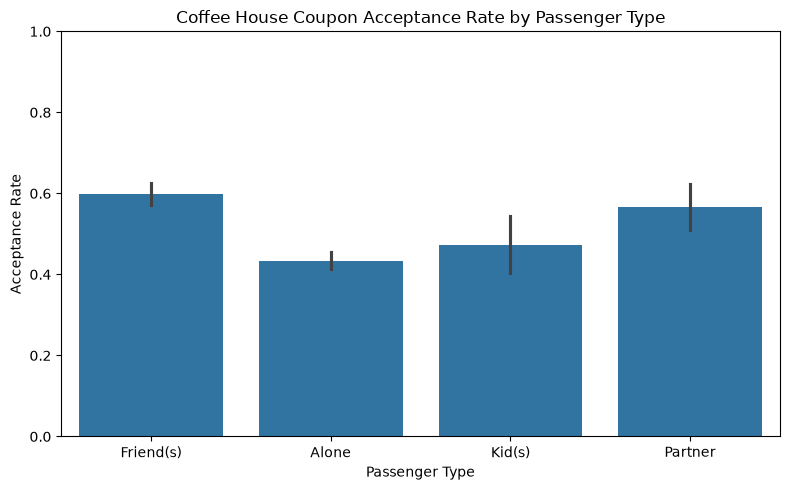

In [19]:
# Compare Coffee House coupon acceptance by passenger type
coffee_passenger_rates = (
    coffee_coupons.groupby('passanger')['Y']
    .mean()
    .sort_values(ascending=False)
)

print(coffee_passenger_rates)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=coffee_coupons,
    x='passanger',
    y='Y',
    estimator='mean'
)

plt.title('Coffee House Coupon Acceptance Rate by Passenger Type')
plt.xlabel('Passenger Type')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

The overall acceptance rate for Coffee House coupons was about 49.6%. Drivers who visited coffee houses frequently, four or more times per month, accepted the coupons at a much higher rate, about 67.3%, compared with about 44.6% for drivers who visited three or fewer times per month. This suggests that a driver’s usual coffee house habits are strongly related to whether they accept a Coffee House coupon.

Looking at passenger type, the highest acceptance rate was among drivers traveling with friends (59.7%), while the lowest was among drivers traveling alone (43.4%). Overall, Coffee House coupons appear most appealing to people who already visit coffee houses regularly, especially when they are traveling with friends or a partner.

## Findings and Recommendations

### Findings

In this dataset, 56.9% of people accepted the coupon they received. Bar coupons had a lower acceptance rate than the full dataset at 41.2%.

The clearest pattern with bar coupons was how often someone already went to bars. Drivers who went more than three times a month accepted them 76.2% of the time. Drivers who went three or fewer times a month only accepted them 37.3% of the time. Drivers over 25 who went to bars more than once a month also had a much higher acceptance rate than everyone else.

I saw a similar pattern with Coffee House coupons. People who visited coffee houses at least four times a month accepted the coupon 67.3% of the time. For people who went less often, the rate was 44.6%. The highest acceptance rate by passenger type was drivers traveling with friends at 59.7%. The lowest was drivers who were alone at 43.4%.

### Recommendations

Based on this, it makes more sense to send coupons to people who already use that type of business. Bar coupons would likely work better for regular bar visitors than for people who rarely go. Coffee House coupons would probably work better for people who already go to coffee shops often, especially when they are with friends or a partner.

Instead of sending the same coupon to everyone, a business could use information like visit frequency and who the customer is traveling with to make the offers more relevant.